# Властная лексика в языке Фомы Аквинского
## Ноутбук 1. Модели, ближайшие соседи и сходство целевых слов

Сравниваются две модели лемм проекта LiLa: Opera Latina (классическая латынь) и Opera Maiora (сочинения Фомы Аквинского). Главный предмет исследования – словоупотребление Фомы, классический корпус служит фоном и точкой отсчёта.

| Раздел | Что получается | Где в статье |
| --- | --- | --- |
| 4. Фоновое сходство | μ, σ и порог μ + 2σ для каждой модели | «Материалы и методы» |
| 5. Сравнение соседей | совпадение 500 ближайших соседей в двух моделях | Таблица 1 |
| 6. Ближайшие соседи | соседи обозначений власти | Таблица 2, Приложение (Таблица П1) |
| 7. Сходство относительно фона | тепловые карты и наибольшие изменения | Рисунки 3–5 |

Сети и сообщества – во втором ноутбуке.

## 1. Подготовка среды

In [8]:
# Зависимости устанавливаются один раз из requirements.txt, а не из ноутбука.
# Это исключает незаметное обновление библиотек при повторном запуске.
from importlib.util import find_spec

NEEDED = {
    "numpy": "numpy", "pandas": "pandas", "gensim": "gensim",
    "networkx": "networkx", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "igraph": "igraph", "leidenalg": "leidenalg",
}
missing = [package for module, package in NEEDED.items() if find_spec(module) is None]
if missing:
    raise ImportError(
        "Не установлены библиотеки: " + ", ".join(missing)
        + ". Установите зависимости в терминале из корня репозитория: "
        + "python -m pip install -r requirements.txt"
    )
print("Необходимые библиотеки доступны. Установка в ноутбуке не требуется.")

Необходимые библиотеки доступны. Установка в ноутбуке не требуется.


## 2. Параметры, словарь и загрузка моделей

Перед запуском поместите исходные `.vec`-файлы в `data/models/` либо один раз пропишите их абсолютные пути в `model_paths.json` (образец — `model_paths.example.json`). По умолчанию сети нет: `DOWNLOAD_MISSING_MODELS = False`. При включении загрузки ноутбук делает до трёх попыток и сохраняет незавершённый файл для продолжения. Проверка исходных SHA-256 сохранена. Рисунки сохраняются в папку `figures/` корня репозитория.

Параметры исследования и последующие расчётные ячейки не изменены.

In [9]:
import hashlib, itertools, os, urllib.request, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="n_jobs value")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import seaborn as sns
from gensim.models import KeyedVectors
from IPython.display import display, Markdown

# Ищем корневую папку репозитория независимо от того, откуда запущен Jupyter.
# При нестандартном расположении можно задать переменную AQUINAS_PROJECT_ROOT.
def find_project_root():
    custom = os.environ.get("AQUINAS_PROJECT_ROOT")
    candidates = [Path(custom).expanduser().resolve()] if custom else []
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    for folder in candidates:
        if (folder / "notebooks" / "01_models_neighbours.ipynb").is_file() and (
            folder / "notebooks" / "02_networks.ipynb"
        ).is_file():
            return folder
    raise FileNotFoundError(
        "Не найдена папка проекта с notebooks/01_models_neighbours.ipynb "
        "и notebooks/02_networks.ipynb. Откройте Jupyter из папки репозитория "
        "или задайте переменную окружения AQUINAS_PROJECT_ROOT."
    )

PROJECT_ROOT = find_project_root()
MODEL_DIR = PROJECT_ROOT / "data" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
# По умолчанию работаем только с уже скачанными моделями.
# Сетевую загрузку можно включить явно, изменив False на True.
DOWNLOAD_MISSING_MODELS = False

# Необязательный файл model_paths.json в корне проекта задаёт пути к моделям
# один раз для ОБОИХ ноутбуков. См. model_paths.example.json.
def read_model_paths():
    config_file = PROJECT_ROOT / "model_paths.json"
    if not config_file.is_file():
        return {}
    with config_file.open("r", encoding="utf-8") as stream:
        paths = json.load(stream)
    if not isinstance(paths, dict):
        raise ValueError("model_paths.json должен содержать объект с ключами classical и aquinas")
    return paths

MODEL_PATHS = read_model_paths()

SEED = 42

# --- Модели LiLa (FastText, skip-gram, 100 измерений) --------------------------
MODELS_INFO = {
    "classical": {"label": "Opera Latina",
                  "file": "raw_classical.vec",
                  "url": "https://embeddings.lila-erc.eu/samples/download/fasttext/allLASLA-lemmi-fast-100-SKIP-win5-min5.vec",
                  "sha256": "4252e2d9ce4ea9e89a469f27db88f4a90a02fade998e7a038c4cd05590147f9c"},
    "aquinas":   {"label": "Opera Maiora (Фома Аквинский)",
                  "file": "raw_aquinas.vec",
                  "url": "https://embeddings.lila-erc.eu/samples/download/OperaMaiora/opera-maiora-lemmas_skip_100.vec",
                  "sha256": "05f4a8ce4561370c0737c908a270e6242dbbe4b5c08aaa5523d157c99c7f8767"},
}

# --- Исследовательский словарь (одинаков для обеих моделей) -------------------
# Обозначения власти – десять слов, положение которых исследуется
CORE_TERMS = ["auctoritas", "potestas", "dominium", "imperium", "regnum",
              "gubernatio", "regimen", "principatus", "iurisdictio", "maiestas"]
GROUPS = {
    "обозначения власти": CORE_TERMS,
    "политические агенты и сообщества": ["magistratus", "princeps", "rex", "tyrannus", "dux",
                                         "ciuitas", "respublica", "populus", "plebs", "uulgus",
                                         "senatus", "natio", "gens"],
    "правовая лексика": ["ius", "lex", "iustitia"],
    "теологическая лексика": ["deus", "ecclesia", "prouidentia", "gratia", "fides"],
    "социально-иерархическая лексика": ["dominus", "seruus", "pater", "dominatio", "dignitas"],
}
TERMS = [t for group in GROUPS.values() for t in group]
GROUP_OF = {t: g for g, ts in GROUPS.items() for t in ts}

# --- Параметры анализа ---------------------------------------------------------
TOP_N = 10                      # ближайших соседей в таблице статьи (в Приложении – 15)
K = 500                         # соседей при сравнении двух моделей, как у авторов моделей
N_LEIDEN_RUNS = 50              # запусков алгоритма Лейдена

# --- Рисунки -------------------------------------------------------------------
FIG_DIR, FIG_DPI = PROJECT_ROOT / "figures", 300
FONT = {"term": 11, "core": 13}  # размеры подписей на рисунках сетей
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_style("white")
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})

# --- Загрузка и проверка моделей -------------------------------------------------
# Сначала используются локальные файлы. Пути можно записать один раз
# в model_paths.json, не редактируя код двух ноутбуков.
# Контрольные суммы моделей остаются прежними.
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def validate_model_file(path, info):
    if not path.is_file():
        raise FileNotFoundError(f"Файл модели {info['label']} не найден: {path}")
    if file_sha256(path) != info["sha256"]:
        raise ValueError(
            f"Контрольная сумма не совпадает для модели {info['label']}: {path}. "
            "Убедитесь, что выбран исходный несoвмещённый файл LiLa нужной версии. "
            "Файл не изменён и не удалён."
        )
    return path


def download_model(info):
    # Скачивание необязательно; сетевые повторы не затрагивают научную часть.
    # При разрыве соединения недокачанный файл .part остаётся для возобновления.
    destination = MODEL_DIR / info["file"]
    part = MODEL_DIR / (info["file"] + ".part")
    print(f"Скачивание {info['label']} с LiLa. Файл: {destination}")
    last_error = None
    for attempt in range(1, 4):
        offset = part.stat().st_size if part.exists() else 0
        headers = {"User-Agent": "aquinas-power-lexicon/1.1"}
        if offset:
            headers["Range"] = f"bytes={offset}-"
        try:
            request = urllib.request.Request(info["url"], headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                status = getattr(response, "status", 200)
                # Некоторые серверы игнорируют Range. В этом случае файл
                # записывается заново, чтобы избежать дублирования данных.
                mode = "ab" if offset and status == 206 else "wb"
                with part.open(mode) as output:
                    while True:
                        chunk = response.read(1024 * 1024)
                        if not chunk:
                            break
                        output.write(chunk)
            if file_sha256(part) != info["sha256"]:
                part.unlink(missing_ok=True)
                raise ValueError(
                    f"Загруженная модель {info['label']} имеет неверную SHA-256. "
                    "Проверьте адрес и версию модели LiLa."
                )
            part.replace(destination)
            return destination
        except ValueError:
            raise
        except Exception as exc:
            last_error = exc
            if attempt < 3:
                print(f"Не удалось завершить загрузку (попытка {attempt}/3): {exc}")
                time.sleep(2 * attempt)
    raise RuntimeError(
        f"Загрузить {info['label']} не удалось после трёх попыток: {last_error}. "
        "Укажите путь к ранее скачанной модели в model_paths.json "
        f"или поместите нужный файл в {MODEL_DIR}. "
        "При необходимости повторный запуск может продолжить файл .part."
    ) from last_error


def locate_or_download_model(name, info):
    original_name = info["url"].rstrip("/").split("/")[-1]
    filenames = (info["file"], original_name)

    # Явные пути имеют приоритет над автоматическим поиском.
    if MODEL_PATHS.get(name):
        candidate = Path(os.path.expandvars(str(MODEL_PATHS[name]))).expanduser()
        if not candidate.is_absolute():
            candidate = PROJECT_ROOT / candidate
        candidate = candidate.resolve()
        result = validate_model_file(candidate, info)
        print(f"Локальная модель {info['label']}: {result}")
        return result

    search_dirs = (MODEL_DIR, PROJECT_ROOT, PROJECT_ROOT / "notebooks", PROJECT_ROOT / "data")
    invalid_files = []
    for folder in search_dirs:
        for filename in filenames:
            candidate = folder / filename
            if not candidate.is_file():
                continue
            if file_sha256(candidate) == info["sha256"]:
                print(f"Локальная модель {info['label']}: {candidate}")
                return candidate
            invalid_files.append(str(candidate))

    if invalid_files:
        raise ValueError(
            f"Найдены файлы с неподходящей SHA-256 для {info['label']}: "
            + ", ".join(invalid_files)
            + ". Они не изменены. Проверьте название и версию модели."
        )

    if DOWNLOAD_MISSING_MODELS:
        return download_model(info)

    raise FileNotFoundError(
        f"Локальная модель {info['label']} не найдена. Ожидается файл "
        f"{original_name} или {info['file']} в папке {MODEL_DIR}. "
        "Если модель сохранена в другом месте, создайте model_paths.json "
        "по образцу model_paths.example.json в корне репозитория и впишите полный путь к файлу. "
        "Автоматическая загрузка отключена, чтобы избежать тайм-аутов."
    )


# Разрешаем расположение обеих моделей до чтения векторов.
model_files = {name: locate_or_download_model(name, info)
               for name, info in MODELS_INFO.items()}
MODELS = {name: KeyedVectors.load_word2vec_format(str(model_files[name]), binary=False)
          for name in MODELS_INFO}

LABEL = {n: MODELS_INFO[n]["label"] for n in MODELS}
SHARED = sorted(set(MODELS["classical"].key_to_index) & set(MODELS["aquinas"].key_to_index))

display(pd.DataFrame(
    [(LABEL[n], len(m), m.vector_size) for n, m in MODELS.items()] + [("Общий словарь", len(SHARED), "")],
    columns=["Модель", "Лемм в словаре", "Размерность"]).set_index("Модель"))
display(Markdown("**Наличие целевых слов в моделях**"))
display(pd.DataFrame({LABEL[n]: ["да" if t in m else "нет" for t in TERMS] for n, m in MODELS.items()},
                     index=pd.Index(TERMS, name="Целевое слово")).T)

Локальная модель Opera Latina: C:\GitHub\aquinas-power-lexicon\data\models\allLASLA-lemmi-fast-100-SKIP-win5-min5.vec
Локальная модель Opera Maiora (Фома Аквинский): C:\GitHub\aquinas-power-lexicon\data\models\opera-maiora-lemmas_skip_100.vec


,Лемм в словаре,Размерность
Модель,,
Opera Latina,11327,100
Opera Maiora (Фома Аквинский),6724,100
Общий словарь,3950,


**Наличие целевых слов в моделях**

Целевое слово,auctoritas,potestas,dominium,imperium,regnum,gubernatio,regimen,principatus,iurisdictio,maiestas,...,deus,ecclesia,prouidentia,gratia,fides,dominus,seruus,pater,dominatio,dignitas
Opera Latina,да,да,да,да,да,нет,да,да,да,да,...,да,нет,да,да,да,да,да,да,да,да
Opera Maiora (Фома Аквинский),да,да,да,да,да,да,да,да,да,да,...,да,да,да,да,да,да,да,да,да,да


## 3. Вспомогательные функции

Ячейку достаточно выполнить.

In [10]:
def save_figure(fig, name):
    # Показывает рисунок в ноутбуке и сохраняет его в PNG.
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def unit_vectors(model, words):
    # Нормированные векторы для списка лемм (длина каждого вектора равна 1).
    v = np.array([model[w] for w in words], dtype=np.float64)
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def background(model):
    # Фоновое распределение: косинусное сходство всех пар лемм полного словаря модели.
    # Пары перебираются блоками, чтобы не держать в памяти десятки миллионов значений.
    v = model.vectors.astype(np.float32)
    v = v / np.linalg.norm(v, axis=1, keepdims=True)
    total, total_sq, count = 0.0, 0.0, 0
    min_sim, max_sim = np.inf, -np.inf
    for start in range(0, len(v), 1000):
        block = v[start:start + 1000] @ v.T
        for r in range(block.shape[0]):
            row = block[r, start + r + 1:].astype(np.float64)
            if row.size == 0:
                continue
            total += row.sum()
            total_sq += (row ** 2).sum()
            count += row.size
            local_min = row.min()
            local_max = row.max()
            if local_min < min_sim:
                min_sim = local_min
            if local_max > max_sim:
                max_sim = local_max
    mu = total / count
    return {"mu": mu, "sigma": np.sqrt(total_sq / count - mu ** 2), "pairs": count,
            "min": float(min_sim), "max": float(max_sim)}


def background_histogram(model, bins=200, min_sim=None, max_sim=None):
    # Точная гистограмма фонового распределения без сохранения всех парных сходств в памяти.
    v = model.vectors.astype(np.float32)
    v = v / np.linalg.norm(v, axis=1, keepdims=True)
    if min_sim is None or max_sim is None:
        stats = background(model)
        min_sim, max_sim = stats["min"], stats["max"]
    edges = np.linspace(min_sim, max_sim, bins + 1)
    counts = np.zeros(bins, dtype=np.int64)
    total = 0
    for start in range(0, len(v), 1000):
        block = v[start:start + 1000] @ v.T
        for r in range(block.shape[0]):
            row = block[r, start + r + 1:].astype(np.float64)
            if row.size == 0:
                continue
            h, _ = np.histogram(row, bins=edges)
            counts += h
            total += row.size
    density = counts / (total * np.diff(edges))
    centers = (edges[:-1] + edges[1:]) / 2
    return {"edges": edges, "centers": centers, "density": density}


def similarity_table(model, terms):
    # Косинусное сходство всех пар целевых слов, присутствующих в модели.
    present = [t for t in terms if t in model]
    v = unit_vectors(model, present)
    return pd.DataFrame(v @ v.T, index=present, columns=present)

def z_table(name):
    # Сходство целевых слов в стандартных отклонениях от фона модели.
    # 0 – обычный для модели уровень сходства, 2 – порог построения сети (μ + 2σ).
    s = similarity_table(MODELS[name], TERMS)
    a = (s.to_numpy(copy=True) - BACKGROUND[name]["mu"]) / BACKGROUND[name]["sigma"]
    np.fill_diagonal(a, np.nan)
    return pd.DataFrame(a, index=s.index, columns=s.columns)


def looks_form_related(term, neighbour):
    # Отмечает соседей, похожих на слово по написанию (влияние частей слова в FastText).
    from difflib import SequenceMatcher
    m = SequenceMatcher(None, term, neighbour)
    common = m.find_longest_match(0, len(term), 0, len(neighbour)).size
    return m.ratio() >= 0.65 or (common >= 5 and common / min(len(term), len(neighbour)) >= 0.55)


def draw_heatmap(matrix, vmin, vmax):
    fig, ax = plt.subplots(figsize=(15, 13))
    sns.heatmap(matrix, cmap="RdBu_r", center=0, vmin=vmin, vmax=vmax, annot=True, fmt=".1f",
                annot_kws={"size": 7}, linewidths=0.3, linecolor="white", square=True,
                cbar_kws={"shrink": 0.7, "label": "Отклонение от фона модели (в σ)"}, ax=ax)
    edges = np.cumsum([sum(t in matrix.index for t in g) for g in GROUPS.values()])[:-1]
    for e in edges:
        ax.axhline(e, color="black", linewidth=1.5); ax.axvline(e, color="black", linewidth=1.5)
    return fig

print("Функции готовы.")

Функции готовы.


## 4. Фоновое сходство в каждой модели

Для каждой модели вычисляется косинусное сходство всех пар лемм её словаря. Среднее (μ) и стандартное отклонение (σ) этого распределения показывают, какое сходство обычно для данной модели. Порог построения сети во втором ноутбуке – μ + 2σ: в сеть попадают пары, сходство которых необычно высоко для своей модели.

Ниже распределение показано и графически: гистограммы позволяют увидеть различие общего уровня сходства в двух моделях и положение порога μ + 2σ.


,Пар лемм,μ,σ,μ + 2σ
Модель,,,,
Opera Latina,64 144 801,0.360,0.115,0.590
Opera Maiora (Фома Аквинский),22 602 726,0.279,0.108,0.496


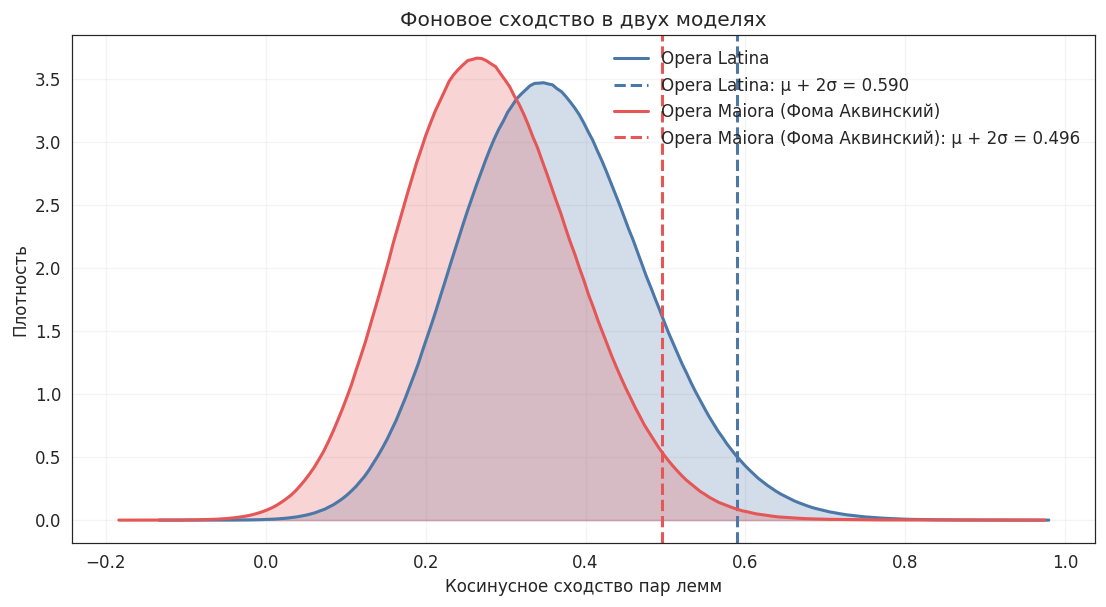

In [11]:
BACKGROUND = {n: background(m) for n, m in MODELS.items()}
display(pd.DataFrame([{"Модель": LABEL[n], "Пар лемм": f"{b['pairs']:,}".replace(",", " "), "μ": round(b["mu"], 3),
                       "σ": round(b["sigma"], 3), "μ + 2σ": round(b["mu"] + 2 * b["sigma"], 3)}
                      for n, b in BACKGROUND.items()]).set_index("Модель"))

HISTS = {n: background_histogram(MODELS[n], bins=200, min_sim=BACKGROUND[n]["min"], max_sim=BACKGROUND[n]["max"])
         for n in MODELS}

fig, ax = plt.subplots(figsize=(12, 6))
for n, color in zip(MODELS.keys(), ["#4C78A8", "#E45756"]):
    h = HISTS[n]
    ax.plot(h["centers"], h["density"], linewidth=2, color=color, label=LABEL[n])
    ax.fill_between(h["centers"], h["density"], alpha=0.25, color=color)
    ax.axvline(BACKGROUND[n]["mu"] + 2 * BACKGROUND[n]["sigma"], color=color, linestyle="--", linewidth=2,
               label=f"{LABEL[n]}: μ + 2σ = {BACKGROUND[n]['mu'] + 2 * BACKGROUND[n]['sigma']:.3f}")
ax.set_xlabel("Косинусное сходство пар лемм")
ax.set_ylabel("Плотность")
ax.set_title("Фоновое сходство в двух моделях")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
save_figure(fig, "background_similarity")


## 5. Сравнение ближайших соседей в двух моделях (Таблица 1)

Как у авторов моделей (Sprugnoli, Moretti, Passarotti 2020, вслед за Gonen et al. 2020), для каждого слова берутся 500 ближайших соседей из общего словаря двух моделей и подсчитывается, сколько из них совпадает. Чем меньше совпадений, тем сильнее различается окружение слова в двух корпусах. Перцентиль показывает долю слов общего словаря, у которых совпадений ещё меньше.

In [12]:
V = {n: unit_vectors(m, SHARED) for n, m in MODELS.items()}
order = {n: np.argsort(-(v @ v.T), axis=1)[:, 1:K + 1] for n, v in V.items()}
overlap = np.array([len(np.intersect1d(order["classical"][i], order["aquinas"][i], assume_unique=True))
                    for i in range(len(SHARED))])
rows = [{"Слово": t, f"Совпадений из {K}": int(overlap[SHARED.index(t)]),
         "Перцентиль": round(100 * (overlap < overlap[SHARED.index(t)]).mean())}
        for t in CORE_TERMS if t in SHARED]
display(Markdown("**Таблица 1. Совпадение ближайших соседей обозначений власти**"))
display(pd.DataFrame(rows).set_index("Слово").sort_values(f"Совпадений из {K}"))
print("Не вошли (нет в одной из моделей):", ", ".join(t for t in CORE_TERMS if t not in SHARED))

**Таблица 1. Совпадение ближайших соседей обозначений власти**

,Совпадений из 500,Перцентиль
Слово,,
regimen,87,13
principatus,102,32
maiestas,110,45
auctoritas,113,50
regnum,119,59
imperium,125,67
dominium,128,72
potestas,151,93
iurisdictio,156,95


Не вошли (нет в одной из моделей): gubernatio


## 6. Ближайшие соседи обозначений власти (Таблица 2, Таблица П1)

Соседи приводятся по всему словарю каждой модели в том виде, в каком их возвращает модель. Знаком † отмечены соседи, похожие на слово по написанию: модели FastText учитывают части слов, и такая близость может отражать словообразование, а не употребление.

In [13]:
def neighbour_table(n_neighbours, with_scores):
    rows = []
    for t in CORE_TERMS:
        row = {"Слово": t}
        for n, m in MODELS.items():
            if t not in m:
                row[LABEL[n]] = "– (нет в модели)"; continue
            row[LABEL[n]] = ", ".join(f"{w}{'†' if looks_form_related(t, w) else ''}" + (f" {s:.3f}" if with_scores else "")
                                      for w, s in m.most_similar(t, topn=n_neighbours))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Слово").style.set_properties(**{"text-align": "left", "white-space": "normal"})

display(Markdown("**Таблица 2. Десять ближайших соседей обозначений власти**"))
display(neighbour_table(TOP_N, with_scores=False))
display(Markdown("**Таблица П1 (Приложение). Пятнадцать ближайших соседей с косинусным сходством**"))
display(neighbour_table(15, with_scores=True))

**Таблица 2. Десять ближайших соседей обозначений власти**

,Opera Latina,Opera Maiora (Фома Аквинский)
Слово,,
auctoritas,"integritas, consensio, grauitas†, exauctoro†, repudio, aucto†, existimatio, rogatio, obtempero, prauitas†","subauctoritas†, auctoritatiuus†, induco, assertiuus, solutio, apostolicus, declaratio, tractator, obiectio, expositio"
potestas,"auctionor, contionor, exceptio, obnuntio, adiudico, intestatus†, obtestatio†, abiudico, enuntio, magistratus","iurisdictio, eximo, minister, dominium, ecclesia, possum, episcopatus, arbiter, resigno, sacerdotalis"
dominium,"lenocinium†, minium†, dominus†, dominor†, alienum, infortunium, munditia, sordide, peruagatus, domicilium†","seruitus, seruus, dominor†, coerceo, potestas, seruitium, dominatio†, conseruus, despoticus, usurpo"
imperium,"imperito†, imperitia†, maroboduus, antiochia, seruitium, externi, arsacidae, abdagaeses, micipsa, imperite†","impero†, imperatiuus†, obedio, despoticus, exequor, nutus, imperitus†, motiuus, subiaceo, regalis"
regnum,"regno†, hiempsal, mithridates, micipsa, cappadoces, numidia, cappadocia, meherdates, phradates, arsacidae","regno†, introeo, regius†, aristocratia, rex, aperio, ciuitas, introitus, regalis, prouincia"
gubernatio,– (нет в модели),"guberno†, gubernatiuus†, gubernator†, gubernatorius†, ordinator, prouisor, regimen, prouidentia, ordinatio†, coordinatio"
regimen,"tegimen†, specimen†, leuamen, conformo, inanimus, quonam, rego, prorsus, informo, magnanimus","praeficio, gubernatiuus, gubernatio, aristocratia, optimas, regitiuus, ciuitas, rector, tyrannicus, regius"
principatus,"principalis†, initium, principium†, princeps†, obtineo, peruagatus, hiempsal, praecello, coitio, consultatio","dominatio, principor†, princeps†, despoticus, prouincia†, archangelus, dominatiuus, regalis, optimas, aristocratia"
iurisdictio,"dictio†, decemuiralis, iurisconsultus, duumuir, rogatio, sortitio, decemuir, priuilegium, exactio, curiatus","degrado, excommunicatio, clauis, forum, episcopus, laicus, absolutio, parochialis, subdiaconatus, indulgentia"


**Таблица П1 (Приложение). Пятнадцать ближайших соседей с косинусным сходством**

,Opera Latina,Opera Maiora (Фома Аквинский)
Слово,,
auctoritas,"integritas 0.696, consensio 0.691, grauitas† 0.675, exauctoro† 0.672, repudio 0.671, aucto† 0.667, existimatio 0.665, rogatio 0.659, obtempero 0.654, prauitas† 0.652, archytas 0.651, emblema 0.649, consensus 0.648, disceptatio 0.647, constantia 0.646","subauctoritas† 0.870, auctoritatiuus† 0.772, induco 0.695, assertiuus 0.671, solutio 0.668, apostolicus 0.662, declaratio 0.659, tractator 0.654, obiectio 0.653, expositio 0.653, probatio 0.652, ceterum 0.649, aio 0.645, improbatio 0.642, auctor† 0.640"
potestas,"auctionor 0.654, contionor 0.653, exceptio 0.649, obnuntio 0.649, adiudico 0.642, intestatus† 0.642, obtestatio† 0.640, abiudico 0.638, enuntio 0.635, magistratus 0.623, testatus† 0.615, denuntio 0.613, iniquitas 0.612, extraordinarius 0.612, imperium 0.611","iurisdictio 0.665, eximo 0.645, minister 0.643, dominium 0.632, ecclesia 0.628, possum 0.624, episcopatus 0.622, arbiter 0.620, resigno 0.620, sacerdotalis 0.620, ordinatio 0.617, ordinarius 0.617, regalis 0.616, inuincibilis 0.615, iudiciarius 0.614"
dominium,"lenocinium† 0.763, minium† 0.737, dominus† 0.693, dominor† 0.691, alienum 0.660, infortunium 0.658, munditia 0.656, sordide 0.654, peruagatus 0.653, domicilium† 0.638, pellicula 0.635, dominans† 0.635, domina† 0.634, indigens 0.630, abiectus 0.629","seruitus 0.684, seruus 0.682, dominor† 0.658, coerceo 0.633, potestas 0.632, seruitium 0.615, dominatio† 0.611, conseruus 0.599, despoticus 0.595, usurpo 0.593, iurisconsultus 0.593, mercatio 0.584, tyrannicus 0.572, patrimonium 0.570, latrocinium† 0.568"
imperium,"imperito† 0.705, imperitia† 0.704, maroboduus 0.700, antiochia 0.694, seruitium 0.694, externi 0.688, arsacidae 0.687, abdagaeses 0.685, micipsa 0.684, imperite† 0.682, puerperium† 0.676, syphax 0.676, iudaei 0.674, regnum 0.672, uonones 0.670","impero† 0.794, imperatiuus† 0.727, obedio 0.724, despoticus 0.718, exequor 0.695, nutus 0.646, imperitus† 0.639, motiuus 0.631, subiaceo 0.630, regalis 0.616, elicitiuus 0.607, persuasibilis 0.594, uis 0.583, potestas 0.580, ordinatio 0.579"
regnum,"regno† 0.739, hiempsal 0.719, mithridates 0.717, micipsa 0.706, cappadoces 0.701, numidia 0.700, cappadocia 0.677, meherdates 0.676, phradates 0.675, arsacidae 0.674, regini† 0.674, antiochus 0.673, arimazes 0.672, imperium 0.672, abdagaeses 0.670","regno† 0.698, introeo 0.688, regius† 0.664, aristocratia 0.638, rex 0.631, aperio 0.627, ciuitas 0.627, introitus 0.625, regalis 0.620, prouincia 0.619, ierusalem 0.602, persa 0.600, intromitto 0.597, possideo 0.594, iechonias 0.594"
gubernatio,– (нет в модели),"guberno† 0.882, gubernatiuus† 0.867, gubernator† 0.863, gubernatorius† 0.781, ordinator 0.762, prouisor 0.733, regimen 0.705, prouidentia 0.705, ordinatio† 0.701, coordinatio 0.698, praeficio 0.695, prouisio 0.689, praesideo 0.677, prouidus 0.673, aristocratia 0.671"
regimen,"tegimen† 0.762, specimen† 0.690, leuamen 0.641, conformo 0.637, inanimus 0.636, quonam 0.634, rego 0.633, prorsus 0.628, informo 0.628, magnanimus 0.624, augmen 0.619, intentatus 0.619, inconsultus 0.611, proiectus 0.609, prorsum 0.609","praeficio 0.738, gubernatiuus 0.713, gubernatio 0.705, aristocratia 0.703, optimas 0.696, regitiuus 0.686, ciuitas 0.683, rector 0.668, tyrannicus 0.668, regius 0.665, subdo 0.665, ordinator 0.664, regalis 0.664, ordinatio 0.661, regnatiuus 0.660"
principatus,"principalis† 0.867, initium 0.757, principium† 0.738, princeps† 0.683, obtineo 0.667, peruagatus 0.660, hiempsal 0.656, praecello 0.649, coitio 0.648, consultatio 0.647, citerior 0.646, transalpinus 0.646, praepotens 0.645, primores 0.642, etiamtum 0.640","dominatio 0.788, principor† 0.784, princeps† 0.758, despoticus 0.747, prouincia† 0.739, archangelus 0.729, dominatiuus 0.720, regalis 0.708, optimas 0.701, aristocratia 0.678, michael 0.665, regnatiuus 0.653, regimen 0.646, tyrannicus 0.631, praesideo 0.629"
iurisdictio,"dictio† 0.878, decemuiralis 0.821, iurisconsultus 0.820, duumuir 0.

## 7. Сходство целевых слов относительно фона (Рисунки 3–5)

Средний уровень сходства в двух моделях различается, поэтому сходство каждой пары выражено в стандартных отклонениях от фона своей модели: z = (сходство − μ) / σ. Значение 0 означает обычное для модели сходство, 2 – порог построения сети. Так значения двух моделей становятся сопоставимыми, и их можно вычитать друг из друга. Чёрные линии разделяют группы словаря.

**Рисунок 3. Сходство целевых слов в модели Opera Latina (отклонение от фона)**

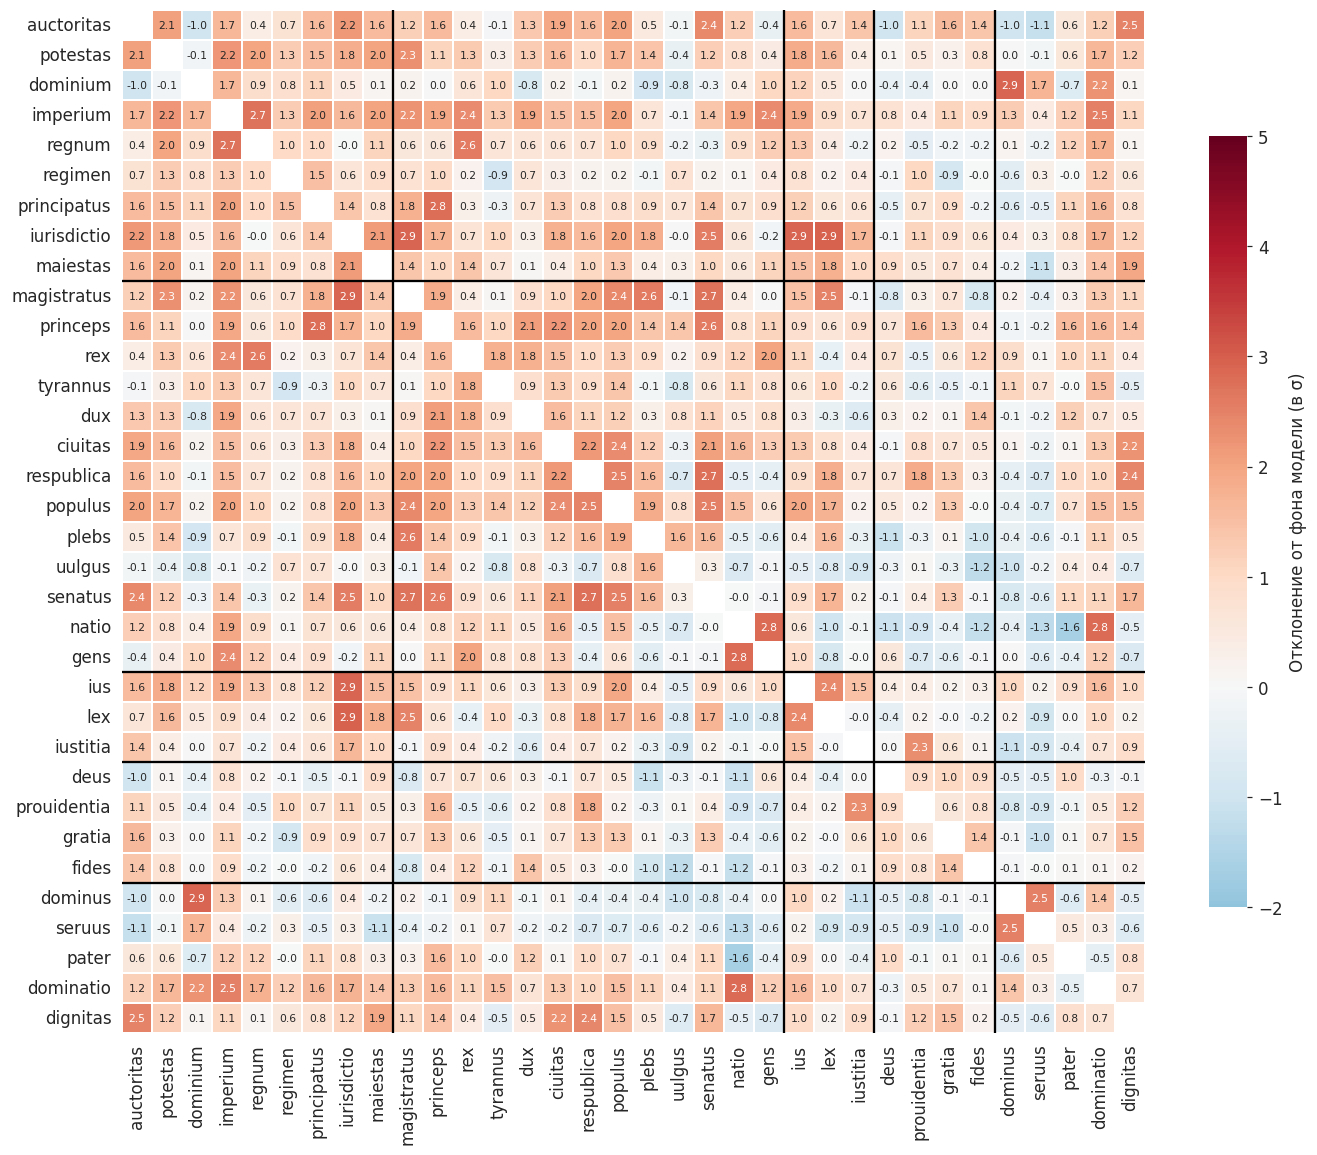

**Рисунок 4. Сходство целевых слов в модели Opera Maiora (Фома Аквинский) (отклонение от фона)**

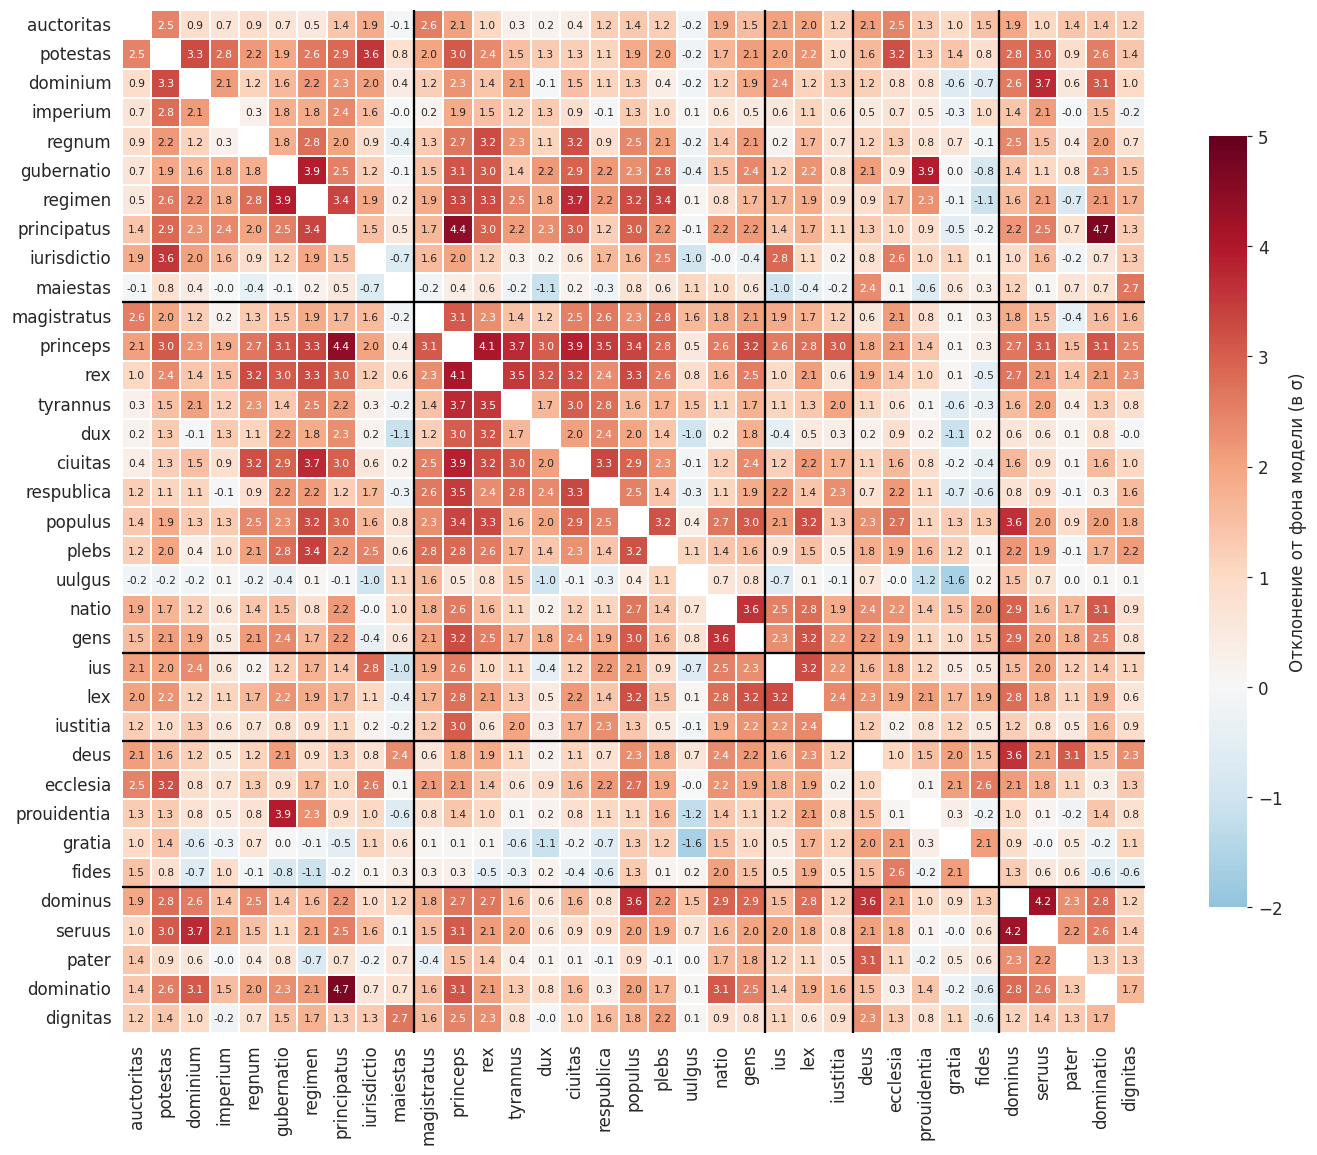

**Рисунок 5. Изменение сходства: Opera Maiora минус Opera Latina**

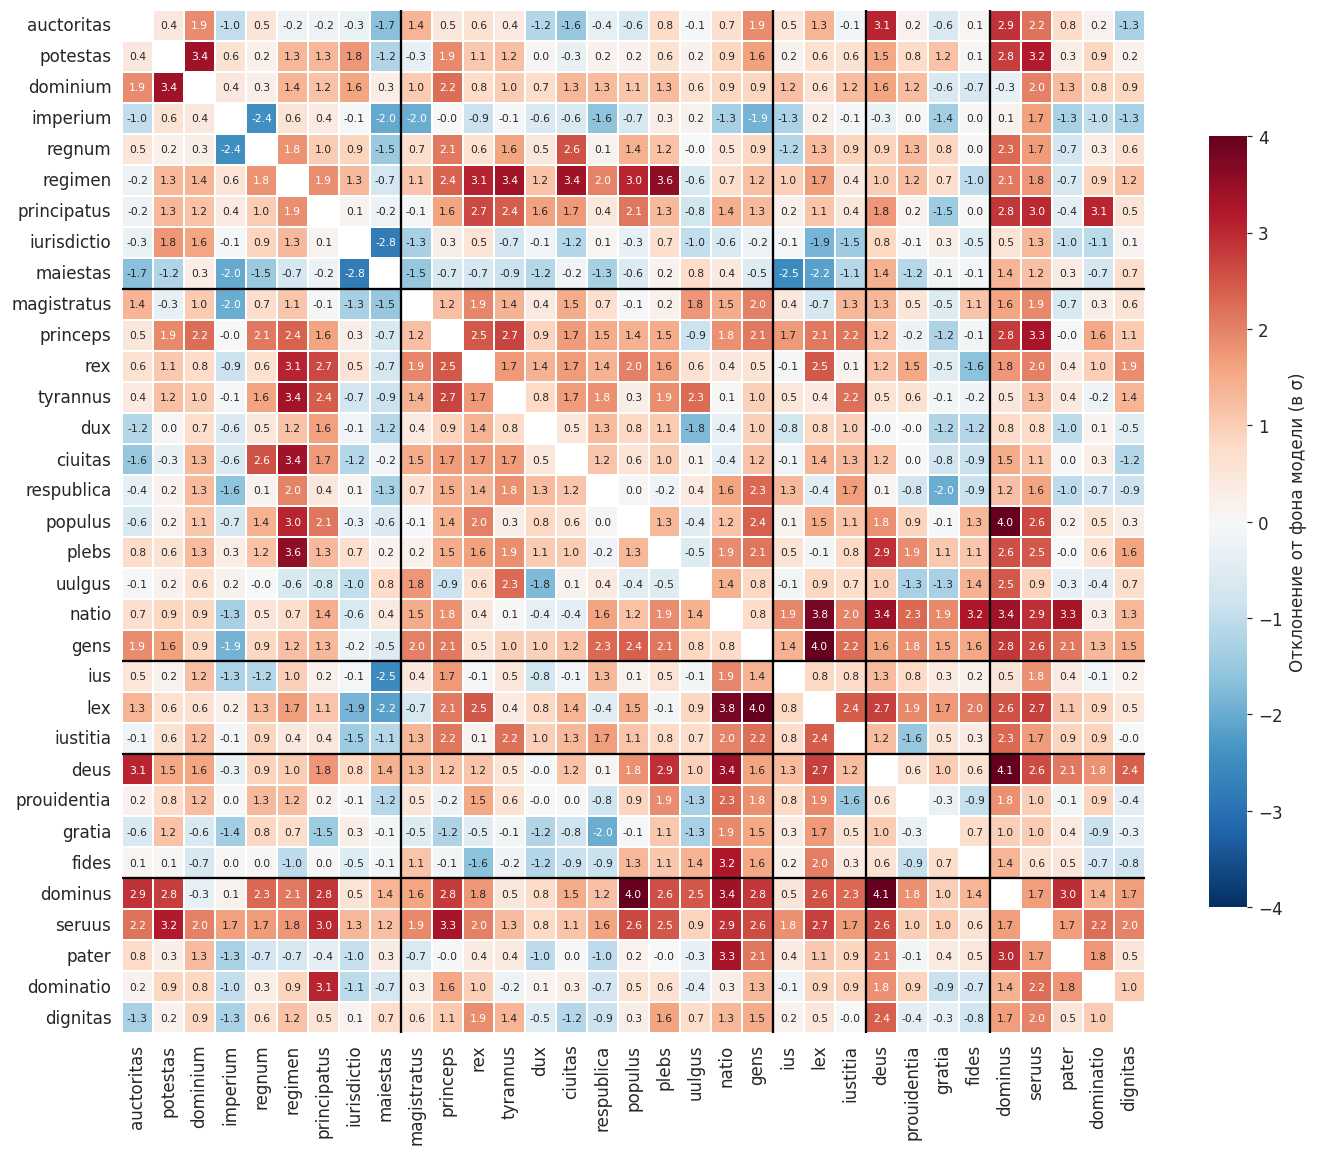

Среднее отклонение от фона по 528 парам: Opera Latina 0.66, Opera Maiora 1.39


**Наибольшие сближения и расхождения**

,Opera Latina,Opera Maiora,Изменение
Пара,,,
deus – dominus,-0.5,3.6,4.1
gens – lex,-0.8,3.2,4.0
populus – dominus,-0.4,3.6,4.0
natio – lex,-1.0,2.8,3.8
regimen – plebs,-0.1,3.4,3.6
natio – deus,-1.1,2.4,3.4
potestas – dominium,-0.1,3.3,3.4
regimen – ciuitas,0.3,3.7,3.4
natio – dominus,-0.4,2.9,3.4


**Среднее изменение сходства слова с остальными целевыми словами**

,maiestas,imperium,iurisdictio,gratia,dux,fides,uulgus,auctoritas,ius,respublica,...,rex,plebs,lex,princeps,regimen,natio,gens,deus,seruus,dominus
Среднее изменение,-0.59,-0.54,-0.14,0.02,0.18,0.21,0.24,0.34,0.37,0.37,...,1.06,1.16,1.2,1.28,1.31,1.35,1.44,1.51,1.89,1.92


In [14]:
Z = {n: z_table(n) for n in MODELS}
common = [t for t in TERMS if t in Z["classical"].index and t in Z["aquinas"].index]
delta = Z["aquinas"].loc[common, common] - Z["classical"].loc[common, common]
for n, number in zip(MODELS, [3, 4]):
    display(Markdown(f"**Рисунок {number}. Сходство целевых слов в модели {LABEL[n]} (отклонение от фона)**"))
    save_figure(draw_heatmap(Z[n], -2, 5), f"Fig{number}_similarity_{n}")
display(Markdown("**Рисунок 5. Изменение сходства: Opera Maiora минус Opera Latina**"))
save_figure(draw_heatmap(delta, -4, 4), "Fig5_similarity_difference")

pairs = list(itertools.combinations(common, 2))
print(f"Среднее отклонение от фона по {len(pairs)} парам: Opera Latina {np.mean([Z['classical'].loc[p] for p in pairs]):.2f}, "
      f"Opera Maiora {np.mean([Z['aquinas'].loc[p] for p in pairs]):.2f}")
display(Markdown("**Наибольшие сближения и расхождения**"))
largest = sorted(pairs, key=lambda p: -abs(delta.loc[p]))[:20]
display(pd.DataFrame([{"Пара": f"{a} – {b}", "Opera Latina": round(Z['classical'].loc[a, b], 1),
                       "Opera Maiora": round(Z['aquinas'].loc[a, b], 1), "Изменение": round(delta.loc[a, b], 1)}
                      for a, b in largest]).set_index("Пара"))
display(Markdown("**Среднее изменение сходства слова с остальными целевыми словами**"))
display(delta.mean(axis=1).sort_values().round(2).to_frame("Среднее изменение").T)